#Base Model for Intrusion Detection

##1. Setup and load the data

In [ ]:
#Setup
%pip -q install xgboost seaborn

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
#Load Data
from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = Path("/content/drive/MyDrive/NIDS")
csv_files = sorted(DATA_DIR.rglob("*.csv"))

print("CSV files found:", len(csv_files))
print("\n".join(str(p) for p in csv_files[:10]))
assert csv_files, "No CSV files found. Check DATA_DIR and extract the dataset ZIP."

Mounted at /content/drive
CSV files found: 1
/content/drive/MyDrive/NIDS/IDS2025.csv


In [ ]:
#When loading multiple datasets
frames = []

for path in csv_files:
    part = pd.read_csv(path, low_memory=False, encoding_errors="replace")
    part.columns = (
        part.columns.astype(str)
        .str.strip()
        .str.replace(r"\s+", "_", regex=True)
    )
    part["_source_file"] = path.stem
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (91830, 81)
Columns: ['Source_Port', 'Destination_Port', 'Protocol', 'Flow_Duration', 'Total_Fwd_Packets', 'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets', 'Total_Length_of_Bwd_Packets', 'Fwd_Packet_Length_Max', 'Fwd_Packet_Length_Min', 'Fwd_Packet_Length_Mean', 'Fwd_Packet_Length_Std', 'Bwd_Packet_Length_Max', 'Bwd_Packet_Length_Min', 'Bwd_Packet_Length_Mean', 'Bwd_Packet_Length_Std', 'Flow_Bytess', 'Flow_Packetss', 'Flow_IAT_Mean', 'Flow_IAT_Std', 'Flow_IAT_Max', 'Flow_IAT_Min', 'Fwd_IAT_Total', 'Fwd_IAT_Mean', 'Fwd_IAT_Std', 'Fwd_IAT_Max', 'Fwd_IAT_Min', 'Bwd_IAT_Total', 'Bwd_IAT_Mean', 'Bwd_IAT_Std', 'Bwd_IAT_Max', 'Bwd_IAT_Min', 'Fwd_PSH_Flags', 'Bwd_PSH_Flags', 'Fwd_URG_Flags', 'Bwd_URG_Flags', 'Fwd_Header_Length', 'Bwd_Header_Length', 'Fwd_Packetss', 'Bwd_Packetss', 'Min_Packet_Length', 'Max_Packet_Length', 'Packet_Length_Mean', 'Packet_Length_Std', 'Packet_Length_Variance', 'FIN_Flag_Count', 'SYN_Flag_Count', 'RST_Flag_Count', 'PSH_Flag_Count', 'ACK_Flag_Count', 

##2. Data overview and label audit
We need confirm the target column and the labels are actually present. The dataset description’s class names may differ from the exact CSV labels.

In [ ]:
target_candidates = [
    c for c in df.columns
    if "label" in c.strip().lower()]

print("Possible target columns:", target_candidates)

Possible target columns: ['newLabel']


In [ ]:
#Set Target Column
TARGET = "newLabel"
df["Label"] = df[TARGET].astype(str).str.strip()

print("Raw label examples:")
print(df[TARGET].astype(str).value_counts(dropna=False).head(40))

Raw label examples:
newLabel
Normal          26185
Dos/DDos        26066
PortScan        25409
Brute Force     10201
Web Attack       2067
Botnet ARES      1873
Infiltration       29
Name: count, dtype: int64


In [ ]:
#Normalize labels into useful broader attack families
def normalize_label(value):
    s = str(value).strip().lower().replace("_", " ").replace("-", " ")

    if s in {"benign", "normal"}:
        return "Normal"
    if "bot" in s:
        return "Botnet"
    if "brute" in s or "patator" in s:
        return "Brute Force"
    if "ddos" in s or s.startswith("dos ") or s == "dos":
        return "DoS/DDoS"
    if "portscan" in s or "port scan" in s:
        return "PortScan"
    if "web attack" in s or "xss" in s or "sql injection" in s:
        return "Web Attack"
    if "infiltration" in s:
        return "Infiltration"
    if "heartbleed" in s:
        return "Heartbleed"

    return s.title()

df = df.dropna(subset=[TARGET]).copy()
df["Label"] = df[TARGET].map(normalize_label)

print(df["Label"].value_counts())
print("\nLabels by source file:")
display(pd.crosstab(df["_source_file"], df["Label"]))

Label
Normal          26185
DoS/DDoS        26066
PortScan        25409
Brute Force     10201
Web Attack       2067
Botnet           1873
Infiltration       29
Name: count, dtype: int64

Labels by source file:


Label,Botnet,Brute Force,DoS/DDoS,Infiltration,Normal,PortScan,Web Attack
_source_file,,,,,,,
IDS2025,1873,10201,26066,29,26185,25409,2067


##3. Explanatory Data Analysis (EDA)

In [ ]:
#Find Duplicates and Missing Fraction = missing rows / total rows
print("Shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

missing = df.isna().mean().sort_values(ascending=False)
display(missing.head(20).to_frame("missing_fraction"))

print("Rows per class:")
display(df["Label"].value_counts().to_frame("rows"))

Shape: (91830, 82)
Exact duplicate rows: 90


,missing_fraction
Flow_Bytess,0.000839
Source_Port,0.000000
Destination_Port,0.000000
Protocol,0.000000
Total_Fwd_Packets,0.000000
Flow_Duration,0.000000
Total_Length_of_Fwd_Packets,0.000000
Total_Length_of_Bwd_Packets,0.000000
Fwd_Packet_Length_Max,0.000000
Total_Backward_Packets,0.000000


Rows per class:


,rows
Label,
Normal,26185
DoS/DDoS,26066
PortScan,25409
Brute Force,10201
Web Attack,2067
Botnet,1873
Infiltration,29


In [ ]:
#Convert flow features that should be numeric and replace infinite values
meta_cols = {"Label", TARGET, "_source_file"}

for col in df.columns:
    if col not in meta_cols:
        converted = pd.to_numeric(df[col], errors="coerce")
        # Convert a column only when most non-empty values parse as numbers.
        nonempty = df[col].notna().sum()
        if nonempty and converted.notna().sum() / nonempty >= 0.90:
            df[col] = converted

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)

print("Numeric features:", len(numeric_cols))
print("Categorical features:",
      df.select_dtypes(include=["object", "category"]).columns.tolist())

Numeric features: 79
Categorical features: ['newLabel', '_source_file', 'Label']


In [ ]:
sample = df[numeric_cols].sample(
    min(20_000, len(df)),
    random_state=42)

corr = sample.corr(method="spearman")

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool))

high_corr_pairs = (
    upper.stack()
    .loc[lambda x: x.abs() > 0.95]
    .sort_values(key=lambda x: x.abs(), ascending=False))

display(high_corr_pairs.head(30).to_frame("spearman"))

,,spearman
Total_Backward_Packets,Subflow_Bwd_Packets,1.000000
Total_Fwd_Packets,Subflow_Fwd_Packets,1.000000
Bwd_Packet_Length_Mean,Avg_Bwd_Segment_Size,1.000000
Fwd_Packet_Length_Mean,Avg_Fwd_Segment_Size,1.000000
Total_Length_of_Bwd_Packets,Subflow_Bwd_Bytes,1.000000
Total_Length_of_Fwd_Packets,Subflow_Fwd_Bytes,1.000000
RST_Flag_Count,ECE_Flag_Count,1.000000
Fwd_PSH_Flags,SYN_Flag_Count,1.000000
Packet_Length_Std,Packet_Length_Variance,1.000000
Active_Mean,Active_Max,0.999975


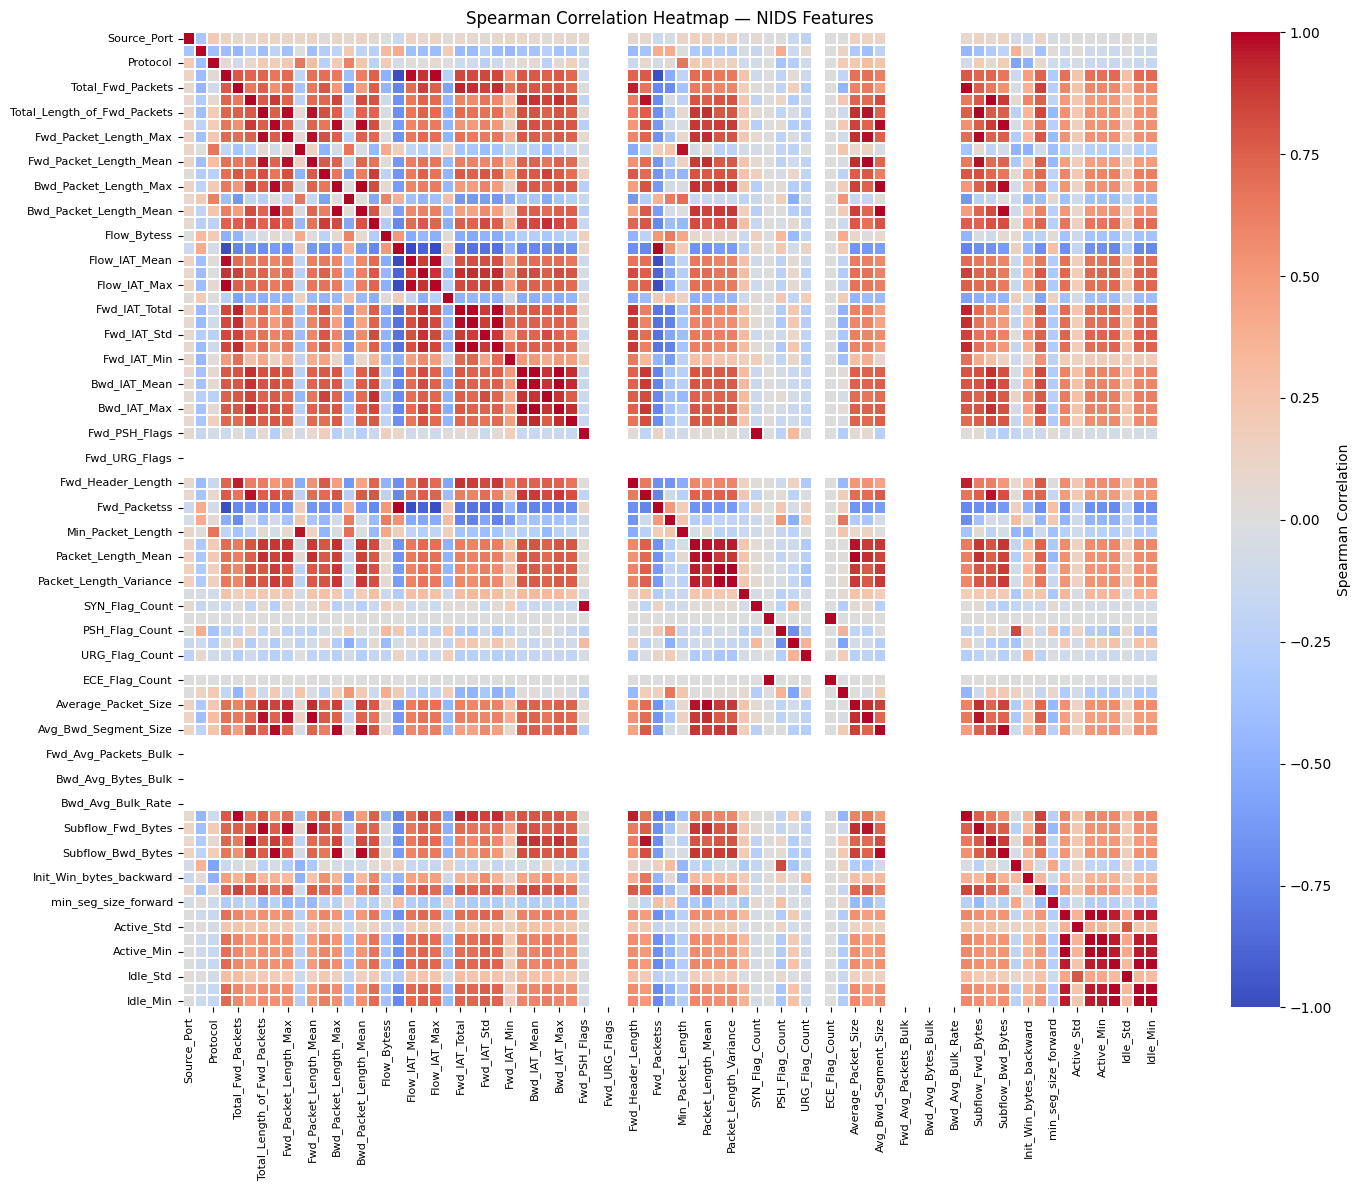

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_signed = sample.corr(method="spearman")

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_signed,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    square=True,
    linewidths=0.1,
    cbar_kws={"label": "Spearman Correlation"})

plt.title("Spearman Correlation Heatmap — NIDS Features")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

##4. Preparing a known-versus-unseen experiment
Web Attack is exclude entirely from model training so that we can test if it detects unknown threats. We also need to split known rows into train, validation, and test sets.

In [ ]:
UNKNOWN_LABELS = {"Web Attack"}  # Choose after reviewing class counts.

missing_unknown = UNKNOWN_LABELS - set(df["Label"].unique())
assert not missing_unknown, f"These held-out labels are absent: {missing_unknown}"

known_df = df[~df["Label"].isin(UNKNOWN_LABELS)].copy()
unknown_df = df[df["Label"].isin(UNKNOWN_LABELS)].copy()

print("Known classes used for training:")
print(known_df["Label"].value_counts())
print("\nHeld-out unknown rows:", len(unknown_df))

Known classes used for training:
Label
Normal          26185
DoS/DDoS        26066
PortScan        25409
Brute Force     10201
Botnet           1873
Infiltration       29
Name: count, dtype: int64

Held-out unknown rows: 2067


In [ ]:
train_val_df, test_known_df = train_test_split(
    known_df,
    test_size=0.20,
    random_state=42,
    stratify=known_df["Label"],
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.20,
    random_state=42,
    stratify=train_val_df["Label"],
)

print("Train:", train_df.shape, "Validation:", val_df.shape,
      "Known test:", test_known_df.shape)

Train: (57448, 82) Validation: (14362, 82) Known test: (17953, 82)


##5. Feature preparation
Drop identifiers, addresses, and timestamps from the first classifier so it is less likely to memorize capture-specific details. Keep _source_file for split auditing, but never feed it to the model.

In [ ]:
def is_identifier_or_time_column(col):
    name = re.sub(r"[^a-z0-9]+", "", col.lower())
    patterns = [
        "flowid", "srcip", "sourceip", "dstip", "destinationip",
        "timestamp", "datetime", "date", "time"
    ]
    return any(p in name for p in patterns)

drop_cols = {
    "Label", TARGET, "_source_file"
}
drop_cols.update(c for c in df.columns if is_identifier_or_time_column(c))

feature_cols = [c for c in df.columns if c not in drop_cols]
X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test_known = test_known_df[feature_cols].copy()
X_test_unknown = unknown_df[feature_cols].copy()

y_train = train_df["Label"]
y_val = val_df["Label"]
y_test_known = test_known_df["Label"]

# Remove columns that are entirely missing in training.
usable_cols = X_train.columns[X_train.notna().any()].tolist()
X_train = X_train[usable_cols]
X_val = X_val[usable_cols]
X_test_known = X_test_known[usable_cols]
X_test_unknown = X_test_unknown[usable_cols]

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

preprocess = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
        ]), cat_cols),
    ],
    remainder="drop",
)

##6. Model B: Random Forest known-class baseline
The classifier learns only the known labels. The confidence threshold is set from validation known flows; flows below it are surfaced as Unknown/Suspicious. This is a practical first rule, but it needs evaluation: Random Forest probabilities aren’t guaranteed to be calibrated, and a known attack can also receive low confidence.

In [ ]:
rf = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=400,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42,
    )),
])

rf.fit(X_train, y_train)

val_probs = rf.predict_proba(X_val)
val_confidence = val_probs.max(axis=1)

# Reject the lowest-confidence 5% of known validation predictions.
UNKNOWN_THRESHOLD = np.quantile(val_confidence, 0.05)
print("Unknown confidence threshold:", UNKNOWN_THRESHOLD)

Unknown confidence threshold: 0.9245435380181092


In [ ]:
#Evaluate on known test rows plus the attack category held out from training
X_test = pd.concat([X_test_known, X_test_unknown], ignore_index=True)
y_test = pd.concat(
    [y_test_known.reset_index(drop=True),
     unknown_df["Label"].reset_index(drop=True)],
    ignore_index=True,
)

test_probs = rf.predict_proba(X_test)
test_confidence = test_probs.max(axis=1)
test_pred = rf.classes_[test_probs.argmax(axis=1)].astype(object)
test_pred[test_confidence < UNKNOWN_THRESHOLD] = "Unknown/Suspicious"

known_mask = ~y_test.isin(UNKNOWN_LABELS)
unknown_mask = y_test.isin(UNKNOWN_LABELS)

print("Known-class performance (known test rows only):")
print(classification_report(
    y_test[known_mask],
    test_pred[known_mask],
    zero_division=0,
))

print("Unknown-vs-known detection performance:")
print(classification_report(
    unknown_mask.astype(str),
    pd.Series(test_pred).eq("Unknown/Suspicious").astype(str),
    zero_division=0,
))

print("Held-out attack flagged as unknown:",
      np.mean(test_pred[unknown_mask] == "Unknown/Suspicious"))
print("Known flows incorrectly flagged unknown:",
      np.mean(test_pred[known_mask] == "Unknown/Suspicious"))

Known-class performance (known test rows only):
                    precision    recall  f1-score   support

            Botnet       1.00      0.97      0.98       375
       Brute Force       1.00      0.99      1.00      2040
          DoS/DDoS       1.00      0.91      0.95      5213
      Infiltration       1.00      0.17      0.29         6
            Normal       1.00      0.92      0.96      5237
          PortScan       1.00      0.99      1.00      5082
Unknown/Suspicious       0.00      0.00      0.00         0

          accuracy                           0.95     17953
         macro avg       0.86      0.71      0.74     17953
      weighted avg       1.00      0.95      0.97     17953

Unknown-vs-known detection performance:
              precision    recall  f1-score   support

       False       1.00      0.95      0.97     17953
        True       0.68      0.98      0.80      2067

    accuracy                           0.95     20020
   macro avg       0.84      0.

##7. Model C: XGBoost comparison

In [ ]:
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

label_encoder = LabelEncoder()
y_train_id = label_encoder.fit_transform(y_train)

xgb = Pipeline([
    ("preprocess", preprocess),
    ("model", XGBClassifier(
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=42,
    )),
])

xgb.fit(X_train, y_train_id)

# Convert integer class IDs back to the original labels before evaluating.
val_probs_xgb = xgb.predict_proba(X_val)
val_threshold_xgb = np.quantile(val_probs_xgb.max(axis=1), 0.05)

test_probs_xgb = xgb.predict_proba(X_test)
test_conf_xgb = test_probs_xgb.max(axis=1)
test_pred_xgb = label_encoder.inverse_transform(test_probs_xgb.argmax(axis=1)).astype(object)
test_pred_xgb[test_conf_xgb < val_threshold_xgb] = "Unknown/Suspicious"

print("XGBoost held-out attack flagged unknown:",
      np.mean(test_pred_xgb[unknown_mask] == "Unknown/Suspicious"))
print("XGBoost known flows incorrectly flagged unknown:",
      np.mean(test_pred_xgb[known_mask] == "Unknown/Suspicious"))

print("XGBoost - Known-class performance:")
print(classification_report(
    y_test[known_mask],
    test_pred_xgb[known_mask],
    zero_division=0,))

print("XGBoost - Unknown-vs-known detection performance:")
print(classification_report(
    unknown_mask.astype(str),
    pd.Series(test_pred_xgb).eq("Unknown/Suspicious").astype(str),
    zero_division=0,))

XGBoost held-out attack flagged unknown: 0.9985486211901307
XGBoost known flows incorrectly flagged unknown: 0.05113351528992369
XGBoost - Known-class performance:
                    precision    recall  f1-score   support

            Botnet       1.00      0.92      0.96       375
       Brute Force       1.00      0.99      1.00      2040
          DoS/DDoS       1.00      0.89      0.94      5213
      Infiltration       0.00      0.00      0.00         6
            Normal       1.00      0.95      0.98      5237
          PortScan       1.00      0.99      1.00      5082
Unknown/Suspicious       0.00      0.00      0.00         0

          accuracy                           0.95     17953
         macro avg       0.71      0.68      0.70     17953
      weighted avg       1.00      0.95      0.97     17953

XGBoost - Unknown-vs-known detection performance:
              precision    recall  f1-score   support

       False       1.00      0.95      0.97     17953
        True  

##8. Model A: Autoencoder

In [ ]:
from sklearn.preprocessing import RobustScaler

normal_train_mask = y_train.eq("Normal")
normal_val_mask = y_val.eq("Normal")

# Autoencoder learns from Normal training flows only.
X_ae_train_raw = X_train.loc[normal_train_mask].copy()
X_ae_val_raw = X_val.loc[normal_val_mask].copy()

# Keep features observed in the benign training rows.
feature_cols = X_ae_train_raw.columns[
    X_ae_train_raw.notna().any()
].tolist()

X_ae_train_raw = X_ae_train_raw[feature_cols]
X_ae_val_raw = X_ae_val_raw[feature_cols]
X_ae_test_raw = X_test[feature_cols].copy()

# Learn imputation values from benign training data only.
medians = X_ae_train_raw.median()
X_ae_train = X_ae_train_raw.fillna(medians)
X_ae_val = X_ae_val_raw.fillna(medians)
X_ae_test = X_ae_test_raw.fillna(medians)

# Fit the scaler on benign training data only.
scaler = RobustScaler()
X_ae_train_scaled = scaler.fit_transform(X_ae_train)
X_ae_val_scaled = scaler.transform(X_ae_val)
X_ae_test_scaled = scaler.transform(X_ae_test)

X_ae_train_scaled = np.clip(X_ae_train_scaled, -10, 10)
X_ae_val_scaled = np.clip(X_ae_val_scaled, -10, 10)
X_ae_test_scaled = np.clip(X_ae_test_scaled, -10, 10)

print("Benign training flows:", len(X_ae_train_scaled))
print("Benign validation flows:", len(X_ae_val_scaled))
print("Test flows:", len(X_ae_test_scaled))

Benign training flows: 16759
Benign validation flows: 4189
Test flows: 20020


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

input_dim = X_ae_train_scaled.shape[1]

inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(64, activation="relu")(inputs)
x = layers.Dense(32, activation="relu")(x)
latent = layers.Dense(16, activation="relu")(x)

x = layers.Dense(32, activation="relu")(latent)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(input_dim, activation="linear")(x)

autoencoder = keras.Model(inputs, outputs)
autoencoder.compile(optimizer="adam", loss="mse")

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history = autoencoder.fit(
    X_ae_train_scaled,
    X_ae_train_scaled,
    validation_data=(X_ae_val_scaled, X_ae_val_scaled),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop],
    shuffle=True,
    verbose=1,
)

Epoch 1/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 5.2857 - val_loss: 2.5277
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.7431 - val_loss: 1.2838
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.0073 - val_loss: 0.8502
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.7181 - val_loss: 0.6420
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.5526 - val_loss: 0.5158
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4580 - val_loss: 0.4395
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3960 - val_loss: 0.3858
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3527 - val_loss: 0.3488
Epoch 9/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3225 - val_loss: 0.3220
Epoch 10/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2990 - val_loss: 0.3003
Epoch 11/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2802 - val_loss: 0.2820
Epoch 12/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.

In [ ]:
import numpy as np

def reconstruction_errors(model, scaled_data):
    reconstructed = model.predict(scaled_data, verbose=0)
    return np.mean(np.square(scaled_data - reconstructed), axis=1)

val_errors = reconstruction_errors(autoencoder, X_ae_val_scaled)
threshold = np.quantile(val_errors, 0.99)

print("Anomaly threshold:", threshold)
print("Benign validation flows flagged:",
      f"{(val_errors > threshold).mean():.2%}")

Anomaly threshold: 0.8368443661218535
Benign validation flows flagged: 1.00%


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
)

test_errors = reconstruction_errors(autoencoder, X_ae_test_scaled)
test_pred_anomaly = test_errors > threshold

y_test_attack = y_test.ne("Normal").to_numpy().astype(int)

print(classification_report(
    y_test_attack,
    test_pred_anomaly.astype(int),
    target_names=["Normal", "Attack"],
    zero_division=0,
))

print("Confusion matrix [Normal, Attack]:")
print(confusion_matrix(y_test_attack, test_pred_anomaly.astype(int)))

print("Attack average precision:",
      average_precision_score(y_test_attack, test_errors))

              precision    recall  f1-score   support

      Normal       0.28      0.99      0.44      5237
      Attack       0.97      0.11      0.20     14783

    accuracy                           0.34     20020
   macro avg       0.62      0.55      0.32     20020
weighted avg       0.79      0.34      0.26     20020

Confusion matrix [Normal, Attack]:
[[ 5179    58]
 [13142  1641]]
Attack average precision: 0.8779482761244223


In [ ]:
display(
    pd.crosstab(
        y_test,
        test_pred_anomaly,
        normalize="index",
    ).rename(columns={
        False: "not flagged",
        True: "flagged as anomalous",
    })
)

col_0,not flagged,flagged as anomalous
Label,,
Botnet,0.600000,0.400000
Brute Force,0.997549,0.002451
DoS/DDoS,0.725302,0.274698
Infiltration,0.000000,1.000000
Normal,0.988925,0.011075
PortScan,0.998229,0.001771
Web Attack,0.981132,0.018868


##9. Feature scores

In [ ]:
from sklearn.feature_selection import mutual_info_classif

X_train_num = X_train[num_cols].copy()
X_train_num = X_train_num.replace([np.inf, -np.inf], np.nan)
X_train_num = X_train_num.fillna(X_train_num.median())

mi = mutual_info_classif(
    X_train_num,
    y_train,
    random_state=42,
)

mi_scores = pd.Series(mi, index=num_cols).sort_values(ascending=False)
display(mi_scores.head(25).to_frame("mutual_information"))

,mutual_information
Destination_Port,1.192036
Packet_Length_Mean,1.118395
Packet_Length_Std,1.116145
Packet_Length_Variance,1.114556
Average_Packet_Size,1.111688
Total_Length_of_Bwd_Packets,1.001428
Subflow_Bwd_Bytes,1.000274
Bwd_Packet_Length_Mean,0.984382
Avg_Bwd_Segment_Size,0.981295
Init_Win_bytes_backward,0.968100
